In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# load dataset
df = pd.read_csv('../data/adhdata.csv')
print(f'Shape: {df.shape}')
print(f'Columns: {df.columns}')
print(f'Data lacks: {df.isnull().values.any()}')

Shape: (2166383, 21)
Columns: Index(['Fp1', 'Fp2', 'F3', 'F4', 'C3', 'C4', 'P3', 'P4', 'O1', 'O2', 'F7',
       'F8', 'T7', 'T8', 'P7', 'P8', 'Fz', 'Cz', 'Pz', 'Class', 'ID'],
      dtype='str')
Data lacks: False


In [7]:
# check dataset balance over adhd and control groups
patient_counts = df.groupby('Class')['ID'].nunique()
print(patient_counts)

Class
ADHD       61
Control    60
Name: ID, dtype: int64


Z literatury naukowej wynika, że kluczowymi wskaźnikami w ADHD są obszary czołowe (np. elektroda Fz) oraz pasma częstotliwości Theta i Beta (wskaźnik TBR). W związku z tym w analizie exploratorycznej przyjrzymy się bliżej rozkładom wartości w kanałach czołowych

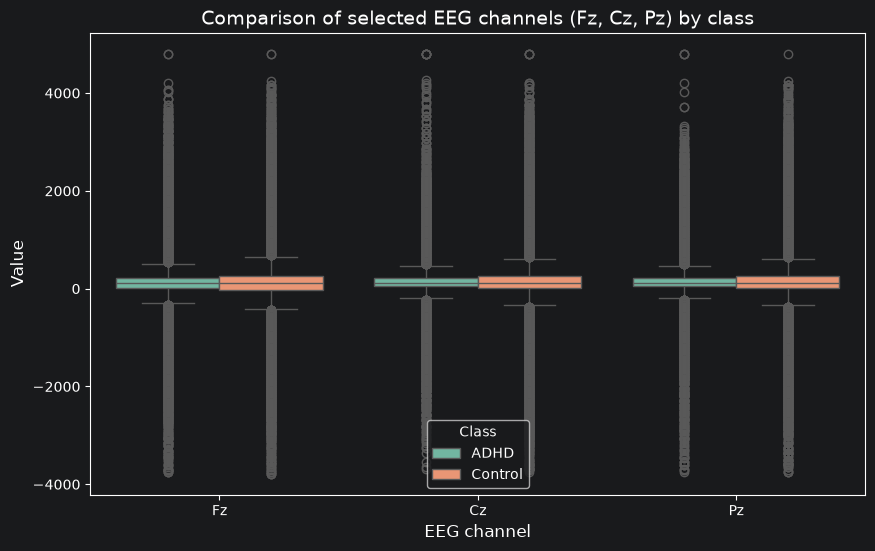

In [8]:
channels_to_plot = ['Fz', 'Cz', 'Pz']
df_melted = df.melt(id_vars=['ID', 'Class'], value_vars=channels_to_plot,
                    var_name='Channel', value_name='Value')

plt.figure(figsize=(10, 6))
sns.boxplot(x='Channel', y='Value', hue='Class', data=df_melted, palette='Set2')

plt.title('Comparison of selected EEG channels (Fz, Cz, Pz) by class', fontsize=14)
plt.xlabel('EEG channel', fontsize=12)
plt.ylabel('Value', fontsize=12)
plt.legend(title='Class')
plt.show()

In [9]:
df.head()

,Fp1,Fp2,F3,F4,C3,C4,P3,P4,O1,O2,...,F8,T7,T8,P7,P8,Fz,Cz,Pz,Class,ID
0,261.0,402.0,16.0,261.0,126.0,384.0,126.0,236.0,52.0,236.0,...,16.0,200.0,494.0,126.0,236.0,121.0,367.0,121.0,ADHD,v10p
1,121.0,191.0,-94.0,85.0,16.0,200.0,126.0,52.0,347.0,273.0,...,-57.0,126.0,347.0,52.0,52.0,15.0,121.0,-19.0,ADHD,v10p
2,-55.0,85.0,-204.0,15.0,-57.0,200.0,52.0,126.0,236.0,200.0,...,-94.0,126.0,420.0,52.0,126.0,-55.0,261.0,85.0,ADHD,v10p
3,191.0,85.0,52.0,50.0,89.0,236.0,163.0,89.0,89.0,89.0,...,-57.0,236.0,420.0,126.0,126.0,15.0,85.0,-55.0,ADHD,v10p
4,-55.0,-125.0,-204.0,-160.0,-204.0,16.0,-241.0,-241.0,89.0,16.0,...,-131.0,89.0,310.0,-57.0,52.0,-55.0,15.0,-336.0,ADHD,v10p


Liczenie t-SNE (to może chwilę potrwać)...


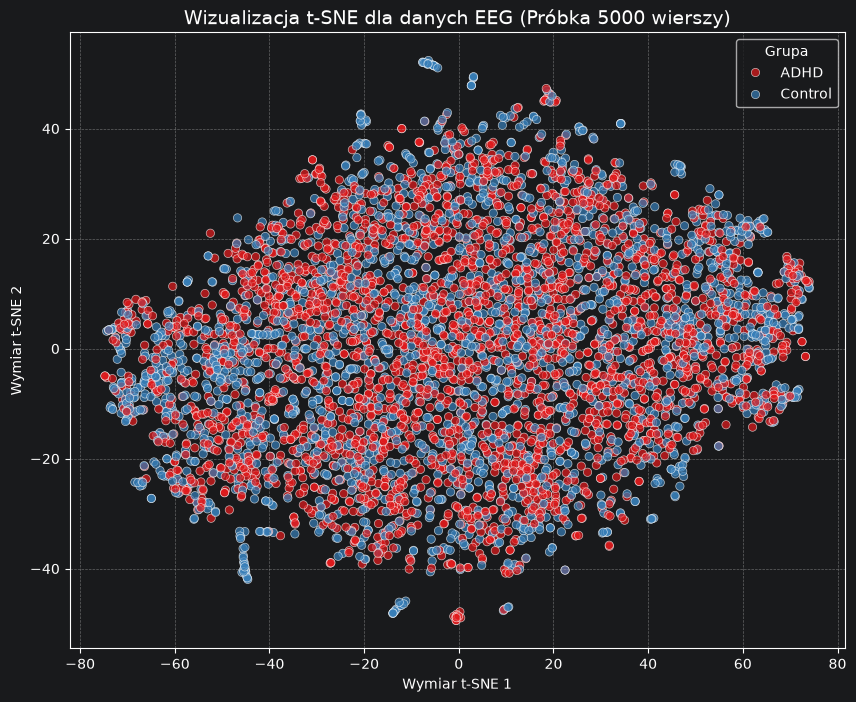

In [12]:
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
import seaborn as sns

# 1. Pobieramy mniejszą próbkę (np. 5000 wierszy), żeby t-SNE policzyło się szybko
df_sample = df.sample(n=5000, random_state=42)

# Definiujemy cechy (kanały) i etykietę
channels = [
    'Fp1', 'Fp2', 'F3', 'F4',
    'C3', 'C4', 'P3', 'P4',
    'O1', 'O2', 'F7', 'F8',
    'T7', 'T8', 'P7', 'P8',
    'Fz', 'Cz', 'Pz'
]
X_sample = df_sample[channels]
y_sample = df_sample['Class']  # 'ADHD' lub 'Control'

# 2. Uruchamiamy algorytm t-SNE (redukcja 19 wymiarów do 2)
print("Liczenie t-SNE (to może chwilę potrwać)...")
tsne = TSNE(n_components=2, random_state=42, perplexity=30, n_iter_without_progress=1000)
X_embedded = tsne.fit_transform(X_sample)

# 3. Przygotowujemy dane do wykresu (tworzymy małą ramkę danych z wynikami 2D)
import pandas as pd
df_tsne = pd.DataFrame(X_embedded, columns=['Dimension 1', 'Dimension 2'])
df_tsne['Class'] = y_sample.values

# 4. Rysujemy wykres za pomocą Seaborn
plt.figure(figsize=(10, 8))
sns.scatterplot(
    x='Dimension 1',
    y='Dimension 2',
    hue='Class',          # Kolory kropek będą zależeć od klasy (ADHD / Control)
    data=df_tsne,
    alpha=0.7,            # Lekka przezroczystość, żeby widzieć nakładające się punkty
    palette='Set1'        # Ładna paleta kolorów
)

# Dodajemy tytuł i etykiety
plt.title('Wizualizacja t-SNE dla danych EEG (Próbka 5000 wierszy)', fontsize=14)
plt.xlabel('Wymiar t-SNE 1')
plt.ylabel('Wymiar t-SNE 2')
plt.legend(title='Grupa')
plt.grid(True, linestyle='--', alpha=0.5)

# Wyświetlamy wykres
plt.show()